# The insurance company: a more realistic model

*Beyond the exercises — an extension of the model from section 1.1 of the scriptum.*

---

The insurance model from exercises 2 and 9 is deliberately simple: claims arrive independently, they
are paid out instantly, and the whole capital is in the account on the first of January. That is what
let the entire year be summed up in a single number.

This notebook asks **what each of those simplifications costs**. We remove them one at a time and
measure the difference:

| Simplification | What replaces it | Section |
|---|---|---|
| the whole capital right at the start | premiums flow in gradually ⟹ the order matters | 1 |
| claims are independent | one accident = several claims at once | 2 |
| | the Lundberg bound for clusters | 3 |
| the payout is instant | approval and payment take some time | 4 |
| claims handling copes with anything | there is a finite number of adjusters ⟹ a queue | 5 |

Every extension keeps a **check**: either an exact formula, or a limiting case in which it returns to
the previous model. Without that, a bug in the simulation could not be told apart from an interesting
result.

It is the classical **Cramér–Lundberg model** with a few practical additions.

In [1]:
import heapq
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def spaces(x, spec=","):
    '''A number with spaces instead of commas as the thousands separator.'''
    return format(x, spec).replace(",", " ")


def check(name, mean, se, exact, k=5):
    print(f"{name}: {spaces(mean, ',.6g')} +- {spaces(se, ',.2g')}  (exact {spaces(exact, ',.6g')})")
    assert abs(mean - exact) <= k * se, name


SCENARIO_A = dict(N=365, p=0.05, L=10_000, K=200_000)

# the number of claims from a single event: one accident, several parties
PARTIES_PER_ACCIDENT = {1: 0.70, 2: 0.20, 3: 0.07, 4: 0.03}
EK = sum(k * q for k, q in PARTIES_PER_ACCIDENT.items())
VarK = sum(k * k * q for k, q in PARTIES_PER_ACCIDENT.items()) - EK**2


def claim(L):
    '''The size of one claim: L·√γ (the inverse transform, exercise 4).'''
    return L * math.sqrt(random.random())


def number_of_parties():
    '''The basic algorithm for a discrete distribution (exercise 3).'''
    s = random.random()
    for k, q in PARTIES_PER_ACCIDENT.items():
        s -= q
        if s < 0:
            return k
    return max(PARTIES_PER_ACCIDENT)


def binomial(N, p):
    '''The number of successes out of N trials via geometric gaps (exercise 3).'''
    lq = math.log(1.0 - p)
    pos, k = -1, 0
    while True:
        pos += 1 + int(math.log(1.0 - random.random()) / lq)
        if pos >= N:
            return k
        k += 1


def ordered_uniforms(n):
    '''n sorted uniform numbers on (0, 1) in O(n) time (exercise 5).'''
    out = [0.0] * n
    u = 1.0
    for k in range(n, 0, -1):
        u *= random.random() ** (1.0 / k)
        out[k - 1] = u
    return out


def year_events(sc, clusters=False):
    '''The claims over a year as a sorted list of (time, size).

    clusters=False: every event = one claim (the model from exercise 9).
    clusters=True:  every event = K claims at the same moment, while the event
                    intensity is divided by E[K], so that the expected number of claims
                    (and hence the expected annual payout) stays the same.
    '''
    N, p, L = sc["N"], sc["p"], sc["L"]
    p_event = p / EK if clusters else p
    times = [t * N for t in ordered_uniforms(binomial(N, p_event))]
    out = []
    for t in times:
        for _ in range(number_of_parties() if clusters else 1):
            out.append((t, claim(L)))
    return out


def theory(sc, clusters=False):
    '''The exact E T and D T of the annual payout.'''
    N, p, L = sc["N"], sc["p"], sc["L"]
    EX, EX2 = 2 * L / 3, L * L / 2
    VarX = EX2 - EX**2
    if not clusters:
        return N * p * EX, N * (p * EX2 - (p * EX) ** 2)
    pe = p / EK                                  # the probability of an event per day
    EY = EK * EX                                 # the mean payout from one event
    VarY = EK * VarX + VarK * EX**2              # the law of total variance
    return N * pe * EY, N * pe * VarY + N * pe * (1 - pe) * EY**2


print(f"the number of parties to one accident: E[K] = {EK:.4f},  D[K] = {VarK:.4f}")
print(f"to keep the expected payout unchanged, the accident intensity drops {EK:.3f}-fold")

the number of parties to one accident: E[K] = 1.4300,  D[K] = 0.5651
to keep the expected payout unchanged, the accident intensity drops 1.430-fold


## 1. The premiums flow in gradually

In exercises 2 and 9 we leaned on a **handy observation**: payouts only accumulate, so ruin happens
exactly when the annual total $T$ exceeds the capital $K$. The order of the claims does not matter.

But that carries a silent assumption: $K$ is the initial capital **plus the entire year's premiums**,
i.e. all the money is in the account on the first of January. In reality the premiums flow in
gradually, and then the company can be sunk by bad luck in the timing — if half the year's claims
arrive in January, there is nothing to pay them from, even if the year as a whole ends in the black.

So at the start the capital is $u_0$, the premiums flow in at a rate of $c$ per day, and the balance
of the account is

$$U(t) = u_0 + c\,t - S(t), \qquad S(t) = \text{the sum of the payouts up to time } t .$$

Ruin occurs if $U(t) < 0$ for **some** $t \le N$. To keep the model comparable with the previous one,
we choose $c$ so that $u_0 + cN = K$: the same money in total, it just flows in gradually.

Because $U$ grows between claims, it is enough to check it **just after each claim**. And here, at
last, the claim times from exercise 5 pay off — as long as only the annual total mattered, they were
not needed.

In [2]:
def ruin(u0, sc, clusters=False, delay=None):
    '''Did ruin occur during the year?

    delay=None: the payout happens the moment the claim arises.
    delay=f:    the payout happens at time t + f(); claims after the end of the year are not paid.
    '''
    N, K_ = sc["N"], sc["K"]
    c = (K_ - u0) / N
    ev = year_events(sc, clusters)
    if delay is not None:
        ev = sorted((t + delay(), x) for t, x in ev)
    S = 0.0
    for t, x in ev:
        if t > N:
            break
        S += x
        if u0 + c * t - S < 0:
            return True
    return False


def p_ruin(u0, sc, M_=40_000, **kw):
    hits = sum(ruin(u0, sc, **kw) for _ in range(M_))
    ph = hits / M_
    return ph, math.sqrt(ph * (1 - ph) / M_)


sc = SCENARIO_A
print(f"scenario A, K = {spaces(sc['K'])} in total; the only thing that changes is how much of it is there at the start\n")
print(f"{'u_0':>10s} {'premiums/year':>15s} {'P(ruin during the year)':>25s}")
u0_list = (200_000, 150_000, 100_000, 60_000, 30_000)
baseline = {}
for u0 in u0_list:
    ph, se = p_ruin(u0, sc)
    baseline[u0] = ph
    print(f"{spaces(u0, '10,d')} {spaces(sc['K'] - u0, '15,d')} {ph:>18.5f} +- {se:.5f}")

print(f"\nu_0 = K is the original model (everything at the start): it comes out at {baseline[200_000]:.5f},")
print("which matches p_u from exercise 9 — the 'handy observation' is thereby verified by simulation.")

scenario A, K = 200 000 in total; the only thing that changes is how much of it is there at the start

       u_0   premiums/year   P(ruin during the year)


   200 000               0            0.00715 +- 0.00042


   150 000          50 000            0.00788 +- 0.00044


   100 000         100 000            0.01010 +- 0.00050


    60 000         140 000            0.01820 +- 0.00067


    30 000         170 000            0.05285 +- 0.00112

u_0 = K is the original model (everything at the start): it comes out at 0.00715,
which matches p_u from exercise 9 — the 'handy observation' is thereby verified by simulation.


The less money the company has at the start, the more the timing matters: at $u_0 = K$ the result is
the same as in exercise 9, at $u_0 = 30\,000$ ruin is roughly seven times as likely.

Let us look at one such year — one that **ends in the black and goes bust anyway**.

found after 23 attempts:
  claims in the year: 25, of which by the end of February: 7
  total annual payout: 171 602  (capital K = 200 000) → in the black at the end of the year
  lowest account balance: -7 543  on day 22 → ruin nonetheless


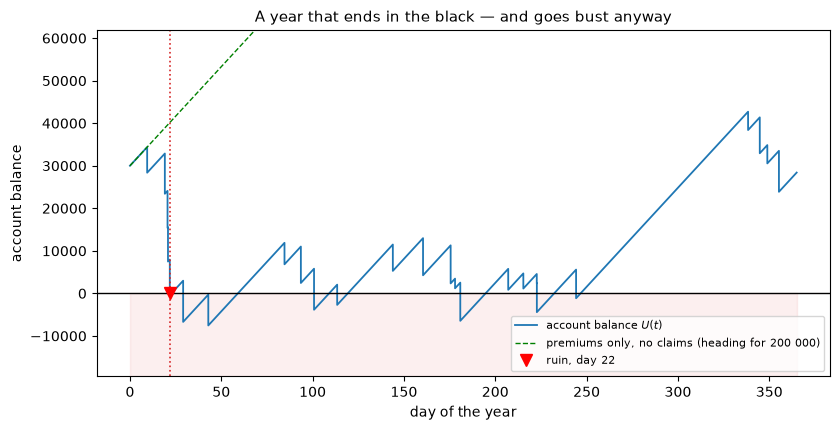

In [3]:
sc = SCENARIO_A
u0 = 30_000
c = (sc["K"] - u0) / sc["N"]

random.seed(12)
for attempt in range(200_000):
    ev = year_events(sc)
    S, lowest, ruin_at = 0.0, u0, None
    for t, x in ev:
        S += x
        balance = u0 + c * t - S
        if balance < 0 and ruin_at is None:
            ruin_at = t
        lowest = min(lowest, balance)
    if ruin_at is not None and S <= sc["K"] and ruin_at < 120:
        break

print(f"found after {attempt + 1} attempts:")
print(f"  claims in the year: {len(ev)}, of which by the end of February: {sum(1 for t, _ in ev if t < 60)}")
print(f"  total annual payout: {spaces(S, ',.0f')}  (capital K = {spaces(sc['K'])}) → in the black at the end of the year")
print(f"  lowest account balance: {spaces(lowest, ',.0f')}  on day {ruin_at:.0f} → ruin nonetheless")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
times, balances, S = [0.0], [u0], 0.0
for t, x in ev:
    times += [t, t]
    balances += [u0 + c * t - S, u0 + c * t - S - x]
    S += x
times.append(sc["N"])
balances.append(u0 + c * sc["N"] - S)
ax.plot(times, balances, lw=1.3, color="tab:blue", label="account balance $U(t)$")
ax.plot([0, sc["N"]], [u0, u0 + c * sc["N"]], "g--", lw=1,
        label=f"premiums only, no claims (heading for {spaces(sc['K'])})")
ax.axhline(0, color="k", lw=1)
ax.axvline(ruin_at, color="tab:red", ls=":", lw=1.2)
ax.plot([ruin_at], [0], "rv", ms=9, label=f"ruin, day {ruin_at:.0f}")
ax.fill_between([0, sc["N"]], [min(balances) - 12_000] * 2, [0, 0], color="tab:red", alpha=0.07)
ax.set_ylim(min(balances) - 12_000, max(balances) * 1.45)
ax.set_xlabel("day of the year")
ax.set_ylabel("account balance")
ax.set_title("A year that ends in the black — and goes bust anyway", fontsize=11)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 2. One accident, several claims

The second simplification: so far every claim was a separate event. In reality one accident often hits
several people at once — a collision of two cars means two claims at the **same moment**.

We take the number of parties from a table (drawn with the basic algorithm from exercise 3):

| parties $K$ | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| probability | 0.70 | 0.20 | 0.07 | 0.03 |

### How to compare fairly

If we simply added clusters and left the accident intensity as it was, the **expected number of
claims** would grow $E[K]$-fold — and the company would go bust more often simply because it pays out
more. That would tell us nothing about clustering.

So we also **divide the accident intensity by $E[K]$**. Both models then cost the same on average, and
the difference in risk is purely down to the clustering.

Theoretically this follows from the law of total variance. If $Y$ is the payout from one accident and
$M$ the number of accidents per year,

$$E\,Y = E[K]\,E[X], \qquad D\,Y = E[K]\,D X + D[K]\,(E X)^2,$$
$$E\,T = E[M]\,E\,Y, \qquad D\,T = E[M]\,D\,Y + D[M]\,(E\,Y)^2 .$$

The expectation comes out the same as before, **the variance does not** — and that is the whole
point.

In [4]:
sc = SCENARIO_A
ET0, VarT0 = theory(sc, clusters=False)
ET1, VarT1 = theory(sc, clusters=True)

print(f"{'model':>26s} {'E T':>12s} {'D T':>18s} {'std. deviation':>16s}")
print(f"{'no clusters (exercise 9)':>26s} {spaces(ET0, ',.0f'):>12s} {spaces(VarT0, ',.0f'):>18s} {spaces(math.sqrt(VarT0), ',.0f'):>16s}")
print(f"{'with clusters':>26s} {spaces(ET1, ',.0f'):>12s} {spaces(VarT1, ',.0f'):>18s} {spaces(math.sqrt(VarT1), ',.0f'):>16s}")
print(f"\nE T is the same (we arranged that), but the standard deviation has grown "
      f"{math.sqrt(VarT1 / VarT0):.2f}-fold.")

# the check: K = 1 has to give exactly the original formula
EK_, VarK_ = EK, VarK
EK, VarK = 1.0, 0.0
assert abs(theory(sc, clusters=True)[1] - VarT0) < 1e-6, "K = 1 must reproduce the original model"
EK, VarK = EK_, VarK_
print("check: for K ≡ 1 the cluster formula gives exactly the original variance ✓")

# and a verification by simulation
n = 100_000
for clusters, label in ((False, "no clusters"), (True, "with clusters")):
    vals = [sum(x for _, x in year_events(sc, clusters)) for _ in range(n)]
    m = sum(vals) / n
    var = sum((v - m) ** 2 for v in vals) / (n - 1)
    ET_, VarT_ = theory(sc, clusters)
    check(f"E T ({label})", m, math.sqrt(var / n), ET_)
    print(f"    D T: simulation {spaces(var, ',.0f')}  (exact {spaces(VarT_, ',.0f')})")

                     model          E T                D T   std. deviation
  no clusters (exercise 9)      121 667        871 944 444           29 529
             with clusters      121 667      1 541 252 914           39 259

E T is the same (we arranged that), but the standard deviation has grown 1.33-fold.
check: for K ≡ 1 the cluster formula gives exactly the original variance ✓


E T (no clusters): 121 680 +- 93  (exact 121 667)
    D T: simulation 869 551 726  (exact 871 944 444)


E T (with clusters): 121 588 +- 1.2e+02  (exact 121 667)
    D T: simulation 1 535 239 761  (exact 1 541 252 914)


The variance has grown by three quarters, even though the company pays out exactly the same on
average. And since ruin is decided by the tail of the distribution, not by its centre, that has to
show up in the risk.

       u_0            no clusters          with clusters   ratio


   100 000        0.01090 +- 0.00052        0.04952 +- 0.00108    4.54


    60 000        0.01800 +- 0.00066        0.07708 +- 0.00133    4.28


    30 000        0.05523 +- 0.00114        0.15748 +- 0.00182    2.85


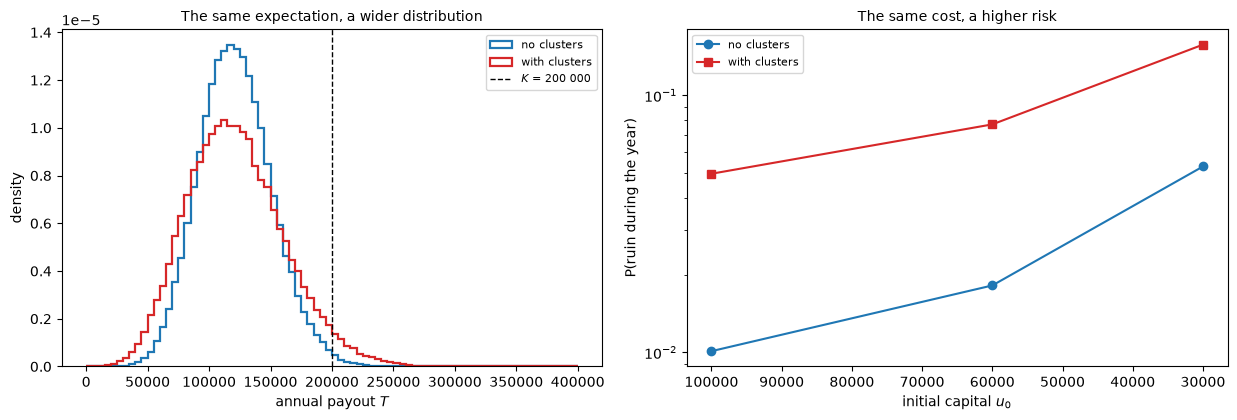

In [5]:
sc = SCENARIO_A
print(f"{'u_0':>10s} {'no clusters':>22s} {'with clusters':>22s} {'ratio':>7s}")
with_clusters = {}
for u0 in (100_000, 60_000, 30_000):
    a, sa = p_ruin(u0, sc, 40_000, clusters=False)
    b, sb = p_ruin(u0, sc, 40_000, clusters=True)
    with_clusters[u0] = b
    print(f"{spaces(u0, '10,d')} {a:>14.5f} +- {sa:.5f} {b:>14.5f} +- {sb:.5f} {b / a:>7.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
n = 60_000
for clusters, color, label in ((False, "tab:blue", "no clusters"), (True, "tab:red", "with clusters")):
    vals = [sum(x for _, x in year_events(sc, clusters)) for _ in range(n)]
    w = 400_000 / 80
    ax.hist(vals, bins=80, range=(0, 400_000), weights=[1 / (len(vals) * w)] * len(vals),
            histtype="step", lw=1.6, color=color, label=label)
ax.axvline(sc["K"], color="k", ls="--", lw=1, label=f"$K$ = {spaces(sc['K'])}")
ax.set_xlabel("annual payout $T$")
ax.set_ylabel("density")
ax.set_title("The same expectation, a wider distribution", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
us = list(with_clusters)
ax.plot(us, [baseline[u] for u in us], "o-", label="no clusters")
ax.plot(us, [with_clusters[u] for u in us], "s-", color="tab:red", label="with clusters")
ax.set_xlabel("initial capital $u_0$")
ax.set_ylabel("P(ruin during the year)")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_title("The same cost, a higher risk", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The left-hand plot shows what happened: both distributions have the same centre, but the one with
clusters is wider — and it is precisely the tail beyond the line $K$ that decides ruin.

The right-hand plot turns that into numbers. **At exactly the same expected cost, ruin is several
times as likely**, purely because the claims come in little groups. This is one of the reasons
insurance companies arrange reinsurance specifically for catastrophes: what matters is not how much is
paid out on average, but how much it fluctuates.

## 3. The Lundberg bound for clusters

In the exercise on ruin we used the Lundberg inequality

$$\psi(u_0) \le e^{-R u_0},$$

where $R$ is the positive root of the equation $\lambda\,(M_X(R) - 1) = c\,R$. For clusters it
generalizes surprisingly elegantly. One **accident** now pays out $Y = X_1 + \dots + X_K$, and since
the $X_i$ are independent of $K$,

$$M_Y(s) = E\big[M_X(s)^K\big] = G_K\big(M_X(s)\big),$$

where $G_K(z) = \sum_k P(K = k)\,z^k$ is the **generating function of the number of parties**. The
Lundberg equation is then

$$\lambda_{\text{accidents}}\,\Big(G_K\big(M_X(R)\big) - 1\Big) = c\,R .$$

For $K \equiv 1$ we have $G_K(z) = z$ and we get the original equation back — that is our check.

In [6]:
def mgf_claim(s, L):
    '''E[e^{sX}] for X = L·√γ, i.e. the density 2x/L² on [0, L].'''
    if abs(s) < 1e-12:
        return 1.0
    return (2.0 / L**2) * (math.exp(s * L) * (L / s - 1 / s**2) + 1 / s**2)


def gk(z):
    '''The generating function of the number of parties.'''
    return sum(q * z**k for k, q in PARTIES_PER_ACCIDENT.items())


def lundberg_R(lam_events, c, L, g=lambda z: z):
    '''The positive root of λ(G_K(M_X(R)) - 1) = cR, by bisection.'''
    f = lambda R: lam_events * (g(mgf_claim(R, L)) - 1) - c * R
    lo, hi = 1e-12, 1e-3
    while f(hi) < 0:
        hi *= 1.5
    for _ in range(300):
        mid = (lo + hi) / 2
        if f(mid) < 0:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


sc = SCENARIO_A
lam_claims = sc["N"] * sc["p"]             # claims per year (the same in both models)
lam_accidents = lam_claims / EK            # accidents per year in the cluster model
EX = 2 * sc["L"] / 3

print(f"claims per year {lam_claims:.2f}; in the cluster model {lam_accidents:.2f} accidents of {EK:.2f} claims each\n")
print(f"{'u_0':>9s} {'c':>10s} | {'R no clusters':>14s} {'bound':>9s} | {'R clusters':>13s} {'bound':>9s} | {'simulation':>11s}")
for u0 in (60_000, 30_000):
    c = sc["K"] - u0
    if c <= lam_claims * EX:
        continue
    R0 = lundberg_R(lam_claims, c, sc["L"])                 # G_K(z) = z
    R1 = lundberg_R(lam_accidents, c, sc["L"], gk)
    m0, m1 = math.exp(-R0 * u0), math.exp(-R1 * u0)
    print(f"{spaces(u0, '9,d')} {spaces(c, '10,d')} | {R0:>14.4e} {m0:>9.5f} | {R1:>13.4e} {m1:>9.5f} | {with_clusters[u0]:>11.5f}")
    assert with_clusters[u0] <= m1, "the Lundberg bound must hold for clusters too"

assert abs(lundberg_R(lam_claims, 140_000, sc["L"], lambda z: z)
           - lundberg_R(lam_claims, 140_000, sc["L"])) < 1e-12
print("\ncheck: G_K(z) = z gives exactly the original R ✓")
print("Clusters lower R and thereby raise the bound — so the theory confirms the higher risk,")
print("not just the simulation showing it.")

claims per year 18.25; in the cluster model 12.76 accidents of 1.43 claims each

      u_0          c |  R no clusters     bound |    R clusters     bound |  simulation
   60 000    140 000 |     3.6370e-05   0.11279 |    2.0535e-05   0.29168 |     0.07708
   30 000    170 000 |     8.3552e-05   0.08155 |    4.5813e-05   0.25300 |     0.15748

check: G_K(z) = z gives exactly the original R ✓
Clusters lower R and thereby raise the bound — so the theory confirms the higher risk,
not just the simulation showing it.


## 4. A payout does not take zero time

The third simplification: so far the money was paid the moment the loss occurred. In reality the
company first **handles** the claim (an inspection, the paperwork, the approval) and only then sends
the money. So some time $D$ passes between the accident and the payout.

For now we take $D$ as independent for each claim, $D \sim \operatorname{Exp}$ with a mean of a couple
of weeks. The check: $D = 0$ has to return the previous model.

Before we run it, it is worth **guessing the result**. A delay does not save anything after all, the
total amount is the same…

…except that the money keeps flowing in meanwhile. Every day of postponement is a day on which
premiums are added to the account but no payout is subtracted. **A delay helps the company** — and
quite markedly.

In [7]:
sc = SCENARIO_A
u0 = 30_000
print(f"u_0 = {spaces(u0)}, with clusters, M = 40 000 years\n")
print(f"{'mean delay':>14s} {'P(ruin)':>22s} {'vs. an instant payout':>24s}")
delay_days = (0.0, 7.0, 14.0, 30.0, 60.0, 90.0)
p_delay = []
for d in delay_days:
    kw = dict(clusters=True) if d == 0 else dict(clusters=True, delay=lambda d=d: random.expovariate(1 / d))
    ph, se = p_ruin(u0, sc, 40_000, **kw)
    p_delay.append(ph)
    ratio = "—" if d == 0 else f"{p_delay[0] / ph:.1f}x less"
    print(f"{d:>10.0f} days {ph:>16.5f} +- {se:.5f} {ratio:>24s}")

print("\nCheck: the row with a delay of 0 is exactly the model from section 2 ✓")

u_0 = 30 000, with clusters, M = 40 000 years

    mean delay                P(ruin)    vs. an instant payout


         0 days          0.15768 +- 0.00182                        —


         7 days          0.12105 +- 0.00163                1.3x less


        14 days          0.09842 +- 0.00149                1.6x less


        30 days          0.05820 +- 0.00117                2.7x less


        60 days          0.02165 +- 0.00073                7.3x less


        90 days          0.00790 +- 0.00044               20.0x less

Check: the row with a delay of 0 is exactly the model from section 2 ✓


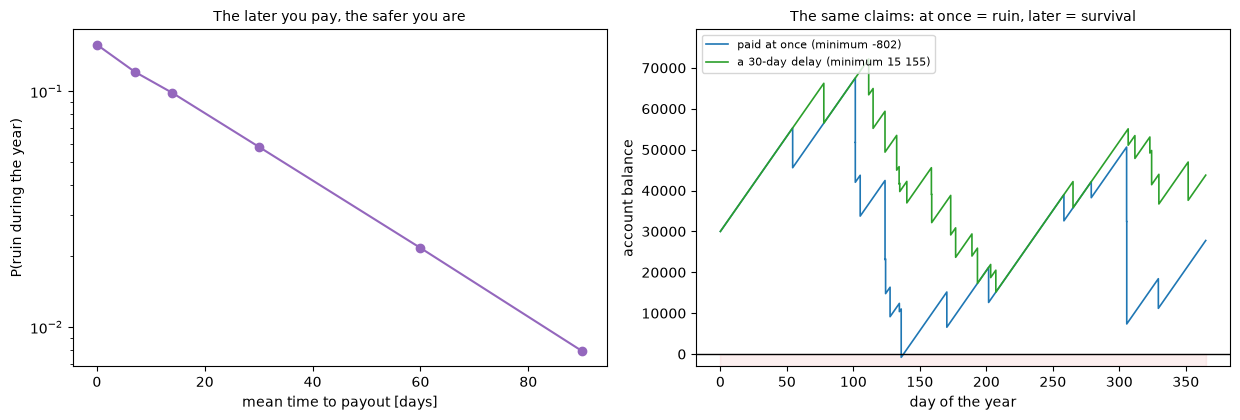

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.plot(delay_days, p_delay, "o-", color="tab:purple")
ax.set_xlabel("mean time to payout [days]")
ax.set_ylabel("P(ruin during the year)")
ax.set_yscale("log")
ax.set_title("The later you pay, the safer you are", fontsize=10)

# why: let us find a year that goes bust with an instant payout and survives with a delay
ax = axes[1]
c = (sc["K"] - u0) / sc["N"]


def balance_path(schedule):
    '''The account balance in time for a given payout schedule; returns (times, balances, lowest).'''
    times, balances, S = [0.0], [u0], 0.0
    for t, x in schedule:
        if t > sc["N"]:
            break
        times += [t, t]
        balances += [u0 + c * t - S, u0 + c * t - S - x]
        S += x
    times.append(sc["N"])
    balances.append(u0 + c * sc["N"] - S)
    return times, balances, min(balances)


random.seed(3)
for attempt in range(200_000):
    ev = year_events(sc, clusters=True)
    now_ = sorted(ev)
    later = sorted((t + random.expovariate(1 / 30.0), x) for t, x in ev)
    c1, s1, min1 = balance_path(now_)
    c2, s2, min2 = balance_path(later)
    if min1 < 0 < min2:                      # instant = ruin, with a delay it survives
        break

ax.plot(c1, s1, lw=1.2, color="tab:blue", label=f"paid at once (minimum {spaces(min1, ',.0f')})")
ax.plot(c2, s2, lw=1.2, color="tab:green", label=f"a 30-day delay (minimum {spaces(min2, ',.0f')})")
ax.axhline(0, color="k", lw=1)
ax.fill_between([0, sc["N"]], [min1 * 1.3 - 2000] * 2, [0, 0], color="tab:red", alpha=0.07)
ax.set_ylim(min1 * 1.3 - 2000, max(max(s1), max(s2)) * 1.10)
ax.set_xlabel("day of the year")
ax.set_ylabel("account balance")
ax.set_title("The same claims: at once = ruin, later = survival", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

The right-hand plot shows the mechanism on a single year: these are **the same claims in the same
order**, merely shifted. The green curve manages to collect premiums in the meantime, so it does not
dip as deep.

But watch out for two things, so that this does not turn into nonsense:

- Part of the payouts is pushed **past the end of the year**, so within our horizon it does not show
  up at all. From the point of view of a single year it looks like a clean gain; in reality it is a
  debt carried forward. An honest answer would need a multi-year model.
- The delay here is **independent of the load**. That is exactly the assumption which in practice is
  the first to fall.

## 5. There is a finite number of adjusters

The fourth simplification: a delay does not fall from the sky. Claims are handled by people and there
is a limited number of them. Claims pile up in a queue for them — and with that we are exactly at a
**queueing system** from the notebook `extra/ch07_queueing`.

The model: claims arrive as the company generates them, $c$ adjusters serve them in order of arrival,
and the handling time is $\operatorname{Exp}$ with a mean of $1/\mu$. The time to payout is **the wait
in the queue plus the handling time**.

The theoretical check: without clusters the arrivals are (almost) Poisson, so for a single adjuster
M/M/1 holds and

$$W = \frac{1}{\mu - \lambda}, \qquad \varrho = \frac{\lambda}{\mu}.$$

**With clusters this stops holding exactly.** The claims arrive in batches, which is the model
$M^{[X]}/M/1$, and a batch waits longer than the same number of evenly spread claims. So the formulas
above will only be approximate — and we measure the difference.

In [9]:
def queue_times(times, adjusters, mean_handling):
    '''A FIFO queue: returns the time from arrival to completion for every claim.'''
    free = [0.0] * adjusters
    heapq.heapify(free)
    times_ = []
    for t in times:
        free_at = heapq.heappop(free)
        end = max(t, free_at) + random.expovariate(1 / mean_handling)
        heapq.heappush(free, end)
        times_.append(end - t)
    return times_


def times_over_years(sc, years, clusters):
    '''The arrival times of claims over several consecutive years.'''
    out = []
    for r in range(years):
        out += [r * sc["N"] + t for t, _ in year_events(sc, clusters)]
    out.sort()
    return out


sc = SCENARIO_A
MEAN_HANDLING = 10.0                          # days per case
lam_day = sc["p"]                             # claims per day
mu_day = 1 / MEAN_HANDLING
print(f"λ = {lam_day:.4f} claims/day, μ = {mu_day:.4f}/day, ϱ = {lam_day / mu_day:.2f}")
print(f"M/M/1 theory:  W = 1/(μ - λ) = {1 / (mu_day - lam_day):.2f} days\n")

print(f"{'arrivals':>16s} {'W from simulation':>19s} {'M/M/1 theory':>16s}")
for clusters, label in ((False, "no clusters"), (True, "with clusters")):
    times = times_over_years(sc, 400, clusters)
    d = queue_times(times, 1, MEAN_HANDLING)
    d = d[len(d) // 5:]                       # drop the run-up (the transient, from the queueing notebook)
    print(f"{label:>16s} {sum(d) / len(d):>14.2f} days {1 / (mu_day - lam_day):>11.2f} days")

print("\nWithout clusters the simulation matches M/M/1. With clusters a claim waits markedly longer,")
print("even though the same number arrive per year — a batch has to wait for itself.")

λ = 0.0500 claims/day, μ = 0.1000/day, ϱ = 0.50
M/M/1 theory:  W = 1/(μ - λ) = 20.00 days

        arrivals   W from simulation     M/M/1 theory
     no clusters          20.08 days       20.00 days
   with clusters          28.17 days       20.00 days

Without clusters the simulation matches M/M/1. With clusters a claim waits markedly longer,
even though the same number arrive per year — a batch has to wait for itself.


What happens when the handling takes longer (ϱ approaches one):

   mean handling       ϱ    W simulation      W theory
       10.0 days   0.500       18.3 days     20.0 days
       14.0 days   0.700       40.4 days     46.7 days
       17.0 days   0.850      139.6 days    113.3 days
       19.0 days   0.950      350.2 days    380.0 days
       19.5 days   0.975      635.7 days    780.0 days


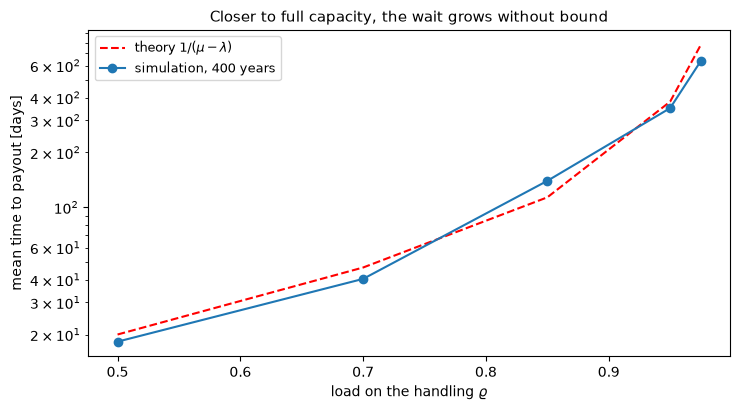


Up to ϱ ≈ 0.7 the simulation matches. Then it drifts away from the theory, and in BOTH
directions — it is not an error in the formula but in the fact that at a high load the queue
settles so slowly that not even 400 years are enough for it. Try running the cell again: the
last rows come out markedly different every time. It is the transient from the queueing notebook.


In [10]:
print("What happens when the handling takes longer (ϱ approaches one):\n")
print(f"{'mean handling':>16s} {'ϱ':>7s} {'W simulation':>15s} {'W theory':>13s}")
loads, W_sim, W_theory = [], [], []
for ms in (10.0, 14.0, 17.0, 19.0, 19.5):
    rho = lam_day * ms
    times = times_over_years(sc, 400, False)
    d = queue_times(times, 1, ms)
    d = d[len(d) // 5:]
    w_s = sum(d) / len(d)
    w_t = 1 / (1 / ms - lam_day)
    loads.append(rho); W_sim.append(w_s); W_theory.append(w_t)
    print(f"{ms:>11.1f} days {rho:>7.3f} {w_s:>10.1f} days {w_t:>8.1f} days")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(loads, W_theory, "r--", label=r"theory $1/(\mu-\lambda)$")
ax.plot(loads, W_sim, "o-", label="simulation, 400 years")
ax.set_xlabel(r"load on the handling $\varrho$")
ax.set_ylabel("mean time to payout [days]")
ax.set_yscale("log")
ax.set_title("Closer to full capacity, the wait grows without bound", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("\nUp to ϱ ≈ 0.7 the simulation matches. Then it drifts away from the theory, and in BOTH")
print("directions — it is not an error in the formula but in the fact that at a high load the queue")
print("settles so slowly that not even 400 years are enough for it. Try running the cell again: the")
print("last rows come out markedly different every time. It is the transient from the queueing notebook.")

The last plot is the second face of the same risk. The company does not have to go bust only by
running out of money — it can also seize up **operationally**: when the handling cannot keep up, the
time to payout grows without bound, clients wait for months and the regulator arrives before
insolvency does.

And look carefully at the last rows of the output. Up to $\varrho \approx 0.7$ the simulation matches
the theory, then it drifts away — and differently every time, once above, once below. It is not an
error in the formula: at a high load the queue settles so slowly that not even 400 years are enough,
so what we are measuring is still the run-up. Run that cell twice and compare the last two rows.

This, incidentally, is a good reason why every extension in this notebook has a check. If we did not
know the formula, almost anything could be concluded from those numbers.

## Summary

| Simplification | What happens when we remove it | The check |
|---|---|---|
| the capital at the start | the order matters; at $u_0 = 30\,000$ ruin is ~7x as likely | $u_0 = K$ returns exercise 9 |
| independent claims | at the **same** expected cost ruin is ~4x as likely | $E T$ matches, $K \equiv 1$ returns the original variance |
| — | the Lundberg bound: $\lambda_{\text{accidents}}(G_K(M_X(R)) - 1) = cR$ | $G_K(z) = z$ returns the original $R$ |
| an instant payout | a delay **helps** the company, the money flows in meanwhile | $D = 0$ returns the previous model |
| unlimited handling | a queue; as $\varrho \to 1$ the wait grows without bound | without clusters M/M/1 matches |

Three things to take away:

1. **It is the variance that decides, not the expectation.** The clusters did not cost a single crown
   more and the risk still jumped several-fold. That is why insurers hedge against catastrophes, not
   against the average.
2. **A simplification is not a lie, but it has a price — and the price can be measured.** Every
   section showed exactly what that particular simplification cost. That is more useful than a model
   "as faithful as possible", in which you do not know what does what.
3. **A more realistic model needs more checks, not fewer.** Every extension here keeps a limiting case
   or a formula. Otherwise a bug passes itself off as a discovery — and the more complicated the
   model, the easier it is not to notice.

### Try it yourself

1. **Rejected claims.** Let the company reject each claim independently with probability $1-q$. Show
   that this is exactly the original model with $p \to pq$, and verify it by simulation. (The lesson:
   not every "extension" is a new model.)
2. **A deductible.** The company pays $\max(X - d, 0)$. Compute $E$ and $D$ of the new payout exactly
   for the density $2r$ and find the $d$ at which the risk of ruin falls by half.
3. Replace the distribution of the number of parties with a heavier one ($K$ up to 10 for a pile-up,
   say) at the same $E[K]$. By how much does the risk grow?
4. Make the delay **depend on the load**: with more open cases, let the handling take longer. Does the
   delay still help?
5. Compute how many adjusters are needed for the mean time to payout to stay under 30 days even in the
   cluster model.
6. Combine sections 4 and 5: use the time from the queue as the payout delay and measure the risk of
   ruin. Do the two findings cancel out, or does one prevail?
7. Extend the model to **five years** and watch whether the delay still helps once the postponed
   payouts come back in the following year.